# Spectral Gradient Descent

In [1]:
# Std Libs
import os

# Third party libs
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.graph_objects as go
import torch

# Data

## Load Dataset

In [2]:
fp = Path("..") / ".." / "data" / "datasets" / "ENB2012_data.csv"
assert os.path.exists(fp)

__df = pd.read_csv(fp, sep=",")
cols_X_raw = [f"X{i}" for i in range(1, 9)]
cols_y = [f"Y{i}" for i in range(1, 3)]
assert set(__df.columns) == set(cols_X_raw) | set(cols_y)

X_raw = __df[cols_X_raw].values.astype("float32")  # Features
print(f"Features: {X_raw.shape}")

Y = __df[cols_y].values.astype("float32")  # Targets
print(f"Targets: {Y.shape}")

Features: (768, 8)
Targets: (768, 2)


## Describes

In [3]:
__df.describe().T

,count,mean,std,min,25%,50%,75%,max
X1,768.0,0.764167,0.105777,0.62,0.6825,0.75,0.8300,0.98
X2,768.0,671.708333,88.086116,514.50,606.3750,673.75,741.1250,808.50
X3,768.0,318.500000,43.626481,245.00,294.0000,318.50,343.0000,416.50
X4,768.0,176.604167,45.165950,110.25,140.8750,183.75,220.5000,220.50
X5,768.0,5.250000,1.751140,3.50,3.5000,5.25,7.0000,7.00
X6,768.0,3.500000,1.118763,2.00,2.7500,3.50,4.2500,5.00
X7,768.0,0.234375,0.133221,0.00,0.1000,0.25,0.4000,0.40
X8,768.0,2.812500,1.550960,0.00,1.7500,3.00,4.0000,5.00
Y1,768.0,22.307201,10.090196,6.01,12.9925,18.95,31.6675,43.10
Y2,768.0,24.587760,9.513306,10.90,15.6200,22.08,33.1325,48.03


In [4]:
pd.DataFrame(X_raw).describe().T

,count,mean,std,min,25%,50%,75%,max
0,768.0,0.764167,0.105777,0.62,0.6825,0.75,0.830,0.98
1,768.0,671.708313,88.086121,514.50,606.3750,673.75,741.125,808.50
2,768.0,318.500000,43.626480,245.00,294.0000,318.50,343.000,416.50
3,768.0,176.604172,45.165951,110.25,140.8750,183.75,220.500,220.50
4,768.0,5.250000,1.751140,3.50,3.5000,5.25,7.000,7.00
5,768.0,3.500000,1.118763,2.00,2.7500,3.50,4.250,5.00
6,768.0,0.234375,0.133221,0.00,0.1000,0.25,0.400,0.40
7,768.0,2.812500,1.550960,0.00,1.7500,3.00,4.000,5.00


In [5]:
df_corrs = pd.DataFrame(X_raw, columns=cols_X_raw).corr().round(4)
df_corrs.abs().style.background_gradient(cmap="viridis", axis=None)

,X1,X2,X3,X4,X5,X6,X7,X8
X1,1.000000,0.991900,0.203800,0.868800,0.827700,0.000000,0.000000,0.000000
X2,0.991900,1.000000,0.195500,0.880700,0.858100,0.000000,0.000000,0.000000
X3,0.203800,0.195500,1.000000,0.292300,0.281000,0.000000,0.000000,0.000000
X4,0.868800,0.880700,0.292300,1.000000,0.972500,0.000000,0.000000,0.000000
X5,0.827700,0.858100,0.281000,0.972500,1.000000,0.000000,0.000000,0.000000
X6,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000
X7,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.213000
X8,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.213000,1.000000


### Features selection

In [6]:
# list_is = [1, 2, 3, 4, 5, 6, 7, 8]
list_is = [1, 3, 6, 7, 8]

cols_X = [f"X{i}" for i in list_is]

X = __df[cols_X].values

# Standardize X
X = (X - X.mean(axis=0)) / X.std(axis=0)

df_corrs2 = pd.DataFrame(X, columns=cols_X).corr().round(4)
df_corrs2.abs().style.background_gradient(cmap="viridis", axis=None)

,X1,X3,X6,X7,X8
X1,1.000000,0.203800,0.000000,0.000000,0.000000
X3,0.203800,1.000000,0.000000,0.000000,0.000000
X6,0.000000,0.000000,1.000000,0.000000,0.000000
X7,0.000000,0.000000,0.000000,1.000000,0.213000
X8,0.000000,0.000000,0.000000,0.213000,1.000000


In [7]:
n1, d = X.shape
n2, p = Y.shape
n = n1

## Multiple Output Linear Regression

### Objective function

[[#Definition]]

Let
- $n, d, p \in \mathbb{N}^*$
- $X \in \mathcal{M}_{n,d}(\mathbb{R})$ features
- $Y \in \mathcal{M}_{n,p}$ targets
- $\forall \beta = (\beta_{i, j})_{(i,j) \in ⟦1,d⟧ \times ⟦1,p⟧} \in \mathcal{M}_{d,p}(\mathbb{R}),\; \|\beta\|_F^2 = \displaystyle \sum_{i,j} \beta_{i,j}^2$ the Frobenius norm

The OLS linear regression objective function is such that $\forall \beta \in \mathcal{M}_{d,p}(\mathbb{R})$
$$F(\beta) = \frac{1}{2np}\|X\beta - Y\|^2$$
$F$ is twice differentiable and
$$\nabla F(\beta) = \frac{1}{np}X^T(X\beta-Y) \quad \text{and} \quad \nabla^2 F(\beta) = \frac{1}{np}X^TX$$

Since $\forall \beta \in \mathcal{M}_{d,p}(\mathbb{R}), \nabla^2 F(\beta) \succeq 0$, F is convex therefore it has a global minimizer $\beta^*$ such that
$$\nabla F(\beta^*) = \frac{1}{np}X^T(X\beta^*-Y) = 0$$

[[#Exact solution]]

Therefore if $X^TX$ is inversible (no multicollinearity), $\beta^*$ is such that:
$$\beta^* = (X^TX)^{-1}X^TY$$

[[#Approximate of solution by gradient descent]]

When $X^\top X$ is not invertible or when $X^\top X$ is too large too inverse easily, an approximation of $\beta^*$ obtained by GD can still be satisfying

One can notice that:
- $\forall \beta \in \mathcal{M}_{d,p}(\mathbb{R}),\; \nabla^2F(\beta) \succeq 0$  
- $F$ is $L$-smooth with $L=\frac{\lambda_{\max}(X^\top X)}{np}$
- $\lambda_{\min}(X^\top X) \gt 0$, So $F$ is $\mu$-strongly convex with $\mu=\frac{\lambda_{\min}(X^\top X)}{np}$ 
- $\mu>0$ so  $\kappa=\frac{L}{\mu} =\frac{\lambda_{\max}(X^\top X)}{\lambda_{\min}(X^\top X)}$

### OLS Solution

In [8]:
G = X.T @ X
cond_nb = np.linalg.cond(G)
rank_g = np.linalg.matrix_rank(G)
pd.DataFrame([[rank_g, cond_nb]], columns=["rank_G", "kappa_G"])

,rank_G,kappa_G
0,5,1.541181


In this case since $G = X^\top X$ is invertible one can compute the OLS solution

In [9]:
beta_star_ols = np.linalg.inv(X.T @ X) @ X.T @ Y
Y_pred_ols = X @ beta_star_ols
Y_target_ts = torch.from_numpy(Y).float()
Y_ols_ts = torch.from_numpy(Y_pred_ols).float()

loss_fn = torch.nn.MSELoss()
mse_ols = float(loss_fn(Y_target_ts, Y_ols_ts).detach().numpy())
pd.DataFrame([mse_ols], columns=["mse_ols"])

,mse_ols
0,570.946472


## Gradient Descent Methods

- $L = \lambda_{max}(\nabla f^2(\beta)) =  \frac{2}{np} \lambda_{max}(X^\top X)$
- $\mu = \lambda_{min}(\nabla f^2(\beta)) =  \frac{2}{np} \lambda_{min}(X^\top X)$
- $\kappa = \frac{L}{\mu}$

In [10]:
spec_gram_x = np.linalg.eigh(G).eigenvalues
lambda_min, lambda_max = np.min(spec_gram_x), np.max(spec_gram_x)
display(pd.DataFrame([[lambda_min, lambda_max]], columns=["lambda_min", "lambda_max"]))

,lambda_min,lambda_max
0,604.443478,931.556522


In [11]:
mu = (2 / (n * p)) * lambda_min
L = (2 / (n * p)) * lambda_max
kappa = L / mu
pd.DataFrame([[L, mu, kappa]], columns=["L", "mu", "kappa"])

,L,mu,kappa
0,1.212964,0.787036,1.541181


### Optimizer kwargs

$F$ is $\mu$-strongly convex and $L$ smooth

<u>Classic GD</u>

- $\alpha^* = \frac{2}{\mu + L}$
- Convergence rate: $O \left(\left(\frac{\kappa - 1}{\kappa + 1}\right)^{2k} \right)$ 
    
    and $F(x_k) - F^* \leq \left(\frac{\kappa - 1}{\kappa + 1}\right)^{2k} \frac{LR^2}{2}$ with $R = \|x_0 - x^* \|^2$
    
    and for a given $\epsilon \in \mathbb{R}^{+*}$,
  $$\left(\frac{\kappa - 1}{\kappa + 1}\right)^{2k} \frac{LR^2}{2} \leq \epsilon \quad \iff \quad k \geq \frac{log\left(\frac{2\epsilon }{LR^2}\right)}{2log\left(\frac{\kappa - 1}{\kappa + 1}\right)}$$

<u>Heavy Ball (HB)</u>

- $\alpha^* = \frac{4}{(\sqrt{L} + \sqrt{\mu})^2}$
- $\beta^* = \left(\frac{\sqrt{\kappa} - 1}{\sqrt{\kappa} + 1}\right)^2$
- For a given $\epsilon \gt 0$ there exists $C_{\epsilon} \gt 0$ such that for all $k \in \mathbb{N}$
$$F(x_k) - F^* \leq C_{\epsilon}\left( \frac{\sqrt{\kappa} - 1}{\sqrt{\kappa} + 1}+ \epsilon\right)^{2k}\|x_0 - x^*\|^2$$
Therefore the convergence rate is 
$$O\left( \left(\frac{\sqrt{\kappa} - 1}{\sqrt{\kappa} + 1}\right)^{2k} \right)$$
And for a given $\delta \in \mathbb{R}^{+*}$, $R = \|x_0 - x^*\|^2$
$$C_{\epsilon}\left( \frac{\sqrt{\kappa} - 1}{\sqrt{\kappa} + 1}+ \epsilon\right)^{2k}R^2 \leq \delta \quad \iff \quad k \geq \frac{log\big(\frac{\delta}{C_{\epsilon}R^2}\big)}{2log\big(\frac{\sqrt{\kappa} - 1}{\sqrt{\kappa} + 1} + \epsilon\big)}$$

In [12]:
epsilon = 1e-10

epochs = int(np.log((2 * epsilon) / (L)) / (2 * np.log((kappa - 1) / (kappa + 1))))
epochs = min(200, epochs)

# GD
lr_gd = 2 / (mu + L)
epochs_gd = int(np.log((2 * epsilon) / (L)) / (2 * np.log((kappa - 1) / (kappa + 1))))
display(
    pd.DataFrame(
        [[lr_gd, epsilon, epochs_gd]], columns=["lr_gd", "epsilon", "epochs_gd"]
    )
)


# HB
lr_hb = 4 / ((np.sqrt(L) + np.sqrt(mu)) ** 2)
mom_hb = ((np.sqrt(kappa) - 1) / (np.sqrt(kappa) + 1)) ** 2
delta = 1e-10
epochs_hb = np.log(epsilon) / (
    2 * np.log((np.sqrt(kappa) - 1) / (np.sqrt(kappa) + 1) + delta)
)
display(
    pd.DataFrame(
        [[lr_hb, mom_hb, delta, epsilon, epochs_hb]],
        columns=["lr_hb", "mom_hb", "delta", "epsilon", "epochs_hb"],
    )
)

# NAG
lr_nag = 1 / L
mom_nag = (np.sqrt(kappa) - 1) / (np.sqrt(kappa) + 1)
epochs_nag = np.log(2 * epsilon / (L + mu)) / np.log(1 - 1 / np.sqrt(kappa))
display(
    pd.DataFrame(
        [[lr_nag, mom_nag, epsilon, epochs_nag]],
        columns=["lr_nag", "mom_nag", "epsilon", "epochs_nag"],
    )
)

# Spectral GD
# TODO: review optimal params for Spectral GD, for the moment we will use
# the same learning rate as classic GD
lr_spectral_gd = lr_gd
mom_spectral_gd = 0
display(
    pd.DataFrame(
        [[lr_spectral_gd, mom_spectral_gd]],
        columns=["lr_spectral_gd", "mom_spectral_gd"],
    )
)


# Epochs: We use the max epoch to observe the convergence of all methods
epochs = int(np.ceil(np.max([epochs_gd, epochs_hb, epochs_nag])))
print(f"Epochs: {epochs}")

dict_kwargs_opt = {
    "GD": {"opt_name": "SGD", "epochs": epochs, "opt_kwargs": {"lr": lr_gd}},
    "HB": {
        "opt_name": "SGD",
        "epochs": epochs,
        "opt_kwargs": {"lr": lr_hb, "momentum": mom_hb},
    },
    "NAG": {
        "opt_name": "SGD",
        "epochs": epochs,
        "opt_kwargs": {"lr": lr_nag, "momentum": mom_nag, "nesterov": True},
    },
    "SpectralGD": {
        "opt_name": "MUON",
        "epochs": epochs,
        "opt_kwargs": {
            "lr": lr_spectral_gd,
            "momentum": mom_spectral_gd,
            "nesterov": False,
            "weight_decay": 0.1,
        },
    },
}

# dict_kwargs_opt

,lr_gd,epsilon,epochs_gd
0,1.0,1.000000e-10,7


,lr_hb,mom_hb,delta,epsilon,epochs_hb
0,1.011603,0.011603,1.000000e-10,1.000000e-10,5.16682


,lr_nag,mom_nag,epsilon,epochs_nag
0,0.824427,0.107718,1.000000e-10,14.062477


,lr_spectral_gd,mom_spectral_gd
0,1.0,0


Epochs: 15


### Run GD

In [13]:
def run_gd(
    **kwargs,
):
    # print(kwargs)
    # Tensor
    X_ts = torch.from_numpy(X).float()
    Y_ts = torch.from_numpy(Y).float()

    # Create Model
    n_samples, in_features = X.shape
    out_features = 1 if len(Y.shape) == 1 else Y.shape[1]
    print(f"In features: {in_features}")
    print(f"Out features: {out_features}")

    model = torch.nn.Linear(
        in_features=in_features,
        out_features=out_features,
        bias=False,
    )

    # Initial weights
    w0 = np.ones((X_ts.shape[1], Y_ts.shape[1]), dtype="float32")
    w0 = torch.as_tensor(w0, dtype=torch.float32).reshape(model.weight.shape)
    with torch.no_grad():
        model.weight.copy_(w0)

    # Loss / Objective function
    criterion = torch.nn.MSELoss()
    epochs = kwargs["epochs"]

    #
    kwargs_optimizer = {
        **{"params": model.parameters()},
        **kwargs["opt_kwargs"],
    }
    opt_name = kwargs["opt_name"]
    if opt_name == "SGD":
        optimizer = torch.optim.SGD(**kwargs_optimizer)
    elif opt_name == "MUON":
        optimizer = torch.optim.Muon(**kwargs_optimizer)
    else:
        raise ValueError(f"Unexpected opt_name: {opt_name}")

    list_weights = []
    list_loss = []

    # Train model
    for epoch in range(epochs):
        # forward pass
        Y_pred = model(X_ts)
        loss = criterion(Y_pred, Y_ts)
        list_loss.append({"epoch": epoch, "loss": loss.item()})

        # backward pass
        loss.backward()
        optimizer.step()

        # empty the gradient
        optimizer.zero_grad()

        # model weights
        weights = model.weight.detach().numpy().ravel().copy()
        list_weights.append(weights)

        # display advancement
        if ((epoch + 1) % 10 == 0) or ((epoch + 1) in [1, epochs]):
            print(f"epoch: {epoch + 1}, loss: {loss.item():4f}")

    Y_pred_gd = model(X_ts).detach().numpy()[:, 0]

    weights = np.array(list_weights)

    dict_res = {
        "X": X_ts,
        "Y": Y_ts,
        "model": model,
        "weights": weights,
        "y_pred_gd": Y_pred_gd,
        "loss": list_loss,
    }
    return dict_res


dict_res_opts = {}
for name in dict_kwargs_opt:
    print(f"{name} Optimizer")
    dict_res_opts[name] = run_gd(**dict_kwargs_opt[name])
    print("+" * 50)

GD Optimizer
In features: 5
Out features: 2
epoch: 1, loss: 625.009460
epoch: 10, loss: 570.946472
epoch: 15, loss: 570.946472
++++++++++++++++++++++++++++++++++++++++++++++++++
HB Optimizer
In features: 5
Out features: 2
epoch: 1, loss: 625.009460
epoch: 10, loss: 570.946472
epoch: 15, loss: 570.946472
++++++++++++++++++++++++++++++++++++++++++++++++++
NAG Optimizer
In features: 5
Out features: 2
epoch: 1, loss: 625.009460
epoch: 10, loss: 570.946472
epoch: 15, loss: 570.946472
++++++++++++++++++++++++++++++++++++++++++++++++++
SpectralGD Optimizer
In features: 5
Out features: 2
epoch: 1, loss: 625.009460
epoch: 10, loss: 600.229065
epoch: 15, loss: 595.285095
++++++++++++++++++++++++++++++++++++++++++++++++++


## Loss

### Loss function at each steps

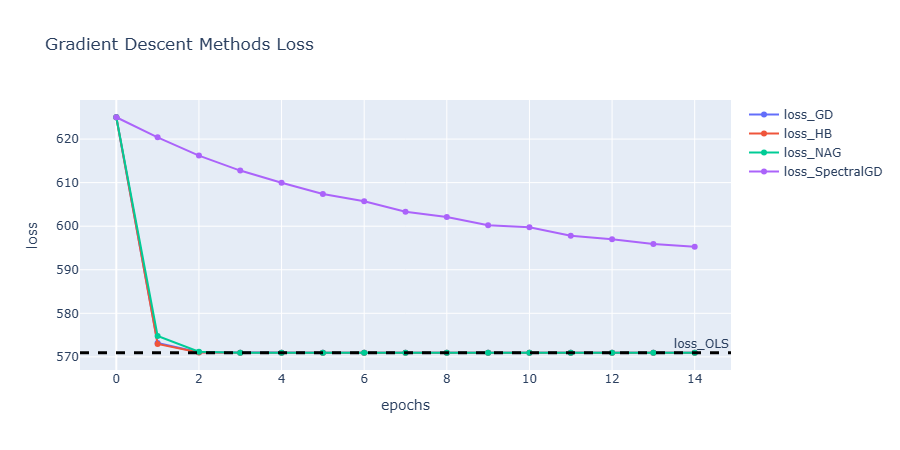

In [14]:
df_loss = None
list_traces = []
fig = go.Figure()
for name in dict_res_opts:
    list_loss = dict_res_opts[name]["loss"]
    df_loss_temp = pd.DataFrame(list_loss)
    fig.add_trace(
        go.Scatter(
            x=df_loss_temp["epoch"],
            y=df_loss_temp["loss"],
            name=f"loss_{name}",
        )
    )

# OLS loss value
fig.add_hline(
    y=float(mse_ols),
    line_width=3,
    line_dash="dash",
    line_color="black",
    annotation_text="loss_OLS",
)
# fig.add_hline(
#     y=float(mse_ols),
#     line_width=3,
#     line_dash="dash",
#     line_color="black",
#     annotation_text="OLS",
# )

# Title, Axes Titles
fig.update_layout(
    title="Gradient Descent Methods Loss",
    xaxis=dict(
        title=dict(
            text="epochs",
        )
    ),
    yaxis=dict(
        title=dict(
            text="loss",
        )
    ),
    width=900,
    height=450,
)
fig.show(renderer="png")
# fig.show()

### Loss function last values

In [15]:
dict_loss = {
    **{"OLS": mse_ols},
    **{name: dict_res_opts[name]["loss"][-1]["loss"] for name in dict_res_opts},
}
pd.DataFrame([dict_loss])

,OLS,GD,HB,NAG,SpectralGD
0,570.946472,570.946472,570.946472,570.946472,595.285095


### Distance between solutions

In [16]:
dict_beta_star = {
    name: dict_res_opts[name]["model"].weight.detach().numpy().copy().T
    for name in dict_res_opts
}

dict_mse = {
    name: ((beta_star_ols - dict_beta_star[name]) ** 2).mean(axis=0).mean()
    for name in dict_res_opts
}
pd.DataFrame([dict_mse])

,GD,HB,NAG,SpectralGD
0,2.366851e-12,2.901281e-12,2.103063e-12,5.817387


## Temporary Conclusions

One can observe that GD,  methods converge quite fast in a couple iterations. 

Which the expected behavior since our problem is well conditioned.

Moreover they are quite close to the optimal solution obtained by OLS.

However with the current params Spectral GD is quite slow to converge. 

<u>Todo</u>

- Review how to set optimal params for Spectral GD
- Add other GD methods
- Test other problems with bad conditioning
- Test other objective functions
